 Data loaded!
Number of customers: 2772
Observation window: 2011-03-05 00:00:00 to 2011-09-01 00:00:00
Churn dataset created!

 Churn Distribution:
Churn
0    1683
1    1089
Name: count, dtype: int64

 Missing Values:
CustomerID        0
Recency           0
Frequency         0
Monetary          0
Tenure            0
AOV               0
AvgGap            0
MaxGap            0
StdGap            0
RecentFreq        0
RecentMonetary    0
ActivityRatio     0
Trend             0
CLV_Proxy         0
RecencyRatio      0
Churn             0
dtype: int64

 Shape: (2772, 16)

 CSV file saved at: C:\Users\hp\Downloads\BIA\E-commerce_Customer_Segmentation_and_Prediction\data\churn_dataset.csv

 Training...


 Training Logistic Regression...
Best Params: {'model__C': 10}
Validation F1: 0.6176 | Accuracy: 0.5505 | ROC-AUC: 0.6820
Confusion Matrix:
 [[ 78 174]
 [ 13 151]]
              precision    recall  f1-score   support

           0       0.86      0.31      0.45       252
           1       0.4

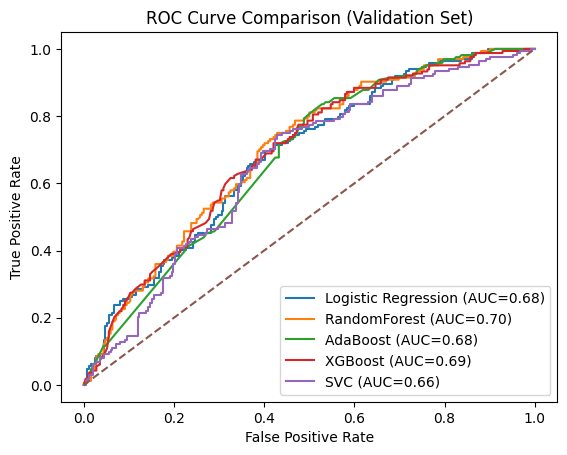


 FINAL TEST RESULTS
F1: 0.6302
Accuracy: 0.5938
ROC-AUC: 0.7283
Confusion Matrix:
 [[103 150]
 [ 19 144]]
              precision    recall  f1-score   support

           0       0.84      0.41      0.55       253
           1       0.49      0.88      0.63       163

    accuracy                           0.59       416
   macro avg       0.67      0.65      0.59       416
weighted avg       0.71      0.59      0.58       416



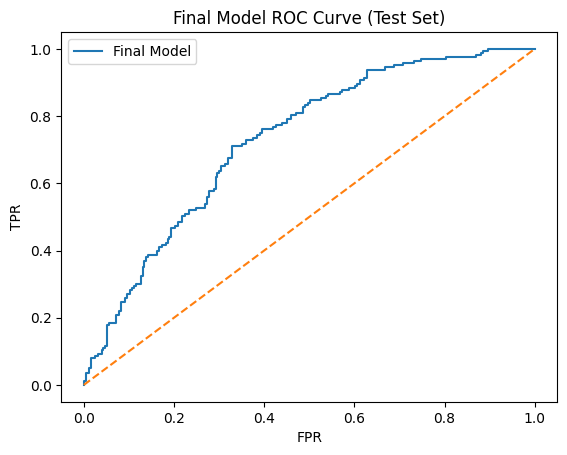


 Model saved!

 SAMPLE FINAL OUTPUT:
   CustomerID  Recency  Frequency  Monetary  R  F  M  RFM_Score  \
0     12347.0       29          3   1603.68  2  2  4          8   
1     12348.0      148          1    367.00  4  1  2          7   
2     12352.0      162          2    280.66  4  1  2          7   
3     12353.0      104          1     89.00  4  1  1          6   
4     12354.0      132          1   1079.40  4  1  3          8   

  RFM_Segment_Label RFM_Customer_Segments  Churn_Pred  Churn_Prob  \
0         Mid Value   Potential Loyalists           0    0.155544   
1         Mid Value   Potential Loyalists           1    0.710587   
2         Mid Value   Potential Loyalists           1    0.574598   
3         Mid Value   Potential Loyalists           1    0.730608   
4         Mid Value   Potential Loyalists           1    0.573145   

  Churn Risk Category            Recommended Action  
0            Low Risk           Maintain engagement  
1           High Risk  Immediate ret

In [1]:
import pandas as pd
import sys
import os

#  SET PROJECT ROOT
PROJECT_PATH = r"C:\Users\hp\Downloads\BIA\E-commerce_Customer_Segmentation_and_Prediction"

sys.path.append(PROJECT_PATH)

# IMPORTS
from src.churn_model_v3 import create_churn_features_pro
from src.churn_training import run_pipeline

# STEP 1: LOAD DATA
data_path = os.path.join(PROJECT_PATH, "data", "known.csv")

df = pd.read_csv(data_path)
print(" Data loaded!")

# STEP 2: CREATE CHURN DATA
churn_df = create_churn_features_pro(
    df,
    snapshot_date="2011-09-01",  
    observation_days=180,
    prediction_days=90
)

print("Churn dataset created!")

# STEP 3: CHECK
print("\n Churn Distribution:")
print(churn_df['Churn'].value_counts())

print("\n Missing Values:")
print(churn_df.isnull().sum())

print("\n Shape:", churn_df.shape)

# STEP 4: SAVE DATASET
save_path = os.path.join(PROJECT_PATH, "data", "churn_dataset.csv")

churn_df.to_csv(save_path, index=False)

print(f"\n CSV file saved at: {save_path}")

# STEP 5: TRAIN
print("\n Training...\n")

run_pipeline(churn_df)

print("\n DONE!")